In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
data = pd.read_csv(r"C:\Users\apkar\OneDrive\Documents\Projects\AIBD\GSE157103_genes.tpm.tsv\GSE157103_genes.tpm.tsv",sep = '\t')


In [3]:
data

,#symbol,C1,C2,C3,C4,C5,C6,C7,C8,C9,...,NC17,NC18,NC19,NC20,NC21,NC22,NC23,NC24,NC25,NC26
0,A1BG,0.49,0.29,0.26,0.45,0.17,0.21,0.49,0.12,0.51,...,0.37,0.33,0.25,0.20,0.40,0.30,0.70,0.75,2.80,0.22
1,A1CF,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.00,0.01,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2,A2M,0.21,0.14,0.03,0.09,0.00,0.08,0.23,0.08,0.88,...,0.07,0.06,0.11,0.01,0.04,0.02,0.02,0.27,0.04,0.28
3,A2ML1,0.04,0.00,0.02,0.07,0.05,0.04,0.03,0.01,0.02,...,0.01,0.00,0.00,0.02,0.02,0.02,0.01,0.00,0.00,0.00
4,A3GALT2,0.07,0.00,0.00,0.00,0.07,0.00,0.07,0.00,0.79,...,0.18,0.00,0.04,0.00,0.00,0.00,0.00,0.06,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19467,ZYG11A,0.06,0.14,0.28,0.27,0.07,0.20,0.19,0.03,0.33,...,0.10,0.06,0.06,0.10,0.06,0.24,0.12,0.14,0.33,0.10
19468,ZYG11B,8.17,8.20,3.62,7.88,5.96,7.14,7.94,7.11,7.93,...,8.82,2.65,2.93,4.58,2.82,1.58,1.57,5.05,1.07,1.25
19469,ZYX,363.01,399.80,430.35,209.25,272.91,246.58,186.24,328.67,366.72,...,475.35,573.54,706.85,712.03,492.63,447.14,748.55,437.62,369.66,577.13
19470,ZZEF1,19.17,15.72,13.95,14.78,8.69,10.58,17.59,10.42,14.67,...,13.38,5.01,4.60,9.06,4.07,3.04,4.55,10.34,1.83,2.08


In [4]:
cl = list(data.columns)
cl.pop(0)
print(len([i for i in cl if i[0] == 'C']))
print(len([i for i in cl if i[0] == 'N']))

100
26


In [5]:
df_t = data.set_index('#symbol').T
df_t.index.name = 'Sample'
df_t = df_t.reset_index()
df_t['Class'] = df_t['Sample'].apply(lambda s: 'Non Covid' if s.startswith('NC') else 'Covid')
cols = ['Sample', 'Class'] + [c for c in df_t.columns if c not in ('Sample', 'Class')]
df_t = df_t[cols]
print(df_t.shape)
print(df_t['Class'].value_counts())
df_t.head()

(126, 19474)
Class
Covid        100
Non Covid     26
Name: count, dtype: int64


#symbol,Sample,Class,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
0,C1,Covid,0.49,0.00,0.21,0.04,0.07,0.0,0.03,18.92,...,2.84,4.22,0.95,1.63,15.51,0.06,8.17,363.01,19.17,6.05
1,C2,Covid,0.29,0.00,0.14,0.00,0.00,0.0,0.05,18.68,...,3.55,12.15,0.60,1.15,15.62,0.14,8.20,399.80,15.72,4.12
2,C3,Covid,0.26,0.00,0.03,0.02,0.00,0.0,0.07,13.85,...,1.34,2.79,0.18,0.32,17.67,0.28,3.62,430.35,13.95,1.81
3,C4,Covid,0.45,0.01,0.09,0.07,0.00,0.0,0.00,22.11,...,3.71,5.87,1.40,2.21,15.61,0.27,7.88,209.25,14.78,7.15
4,C5,Covid,0.17,0.00,0.00,0.05,0.07,0.0,0.00,8.45,...,1.44,4.46,0.28,0.55,9.34,0.07,5.96,272.91,8.69,2.70


In [6]:
genes = data['#symbol']
cc = df_t[df_t['Class'] == 'Covid']
nc = df_t[df_t['Class'] != 'Covid']

In [7]:
avg_expression = [df_t[i].mean() for i in genes]
avg_expression_covid = [cc[i].mean() for i in genes]
avg_expression_non_covid = [nc[i].mean() for i in genes]

Text(0, 0.5, 'Frequencey')

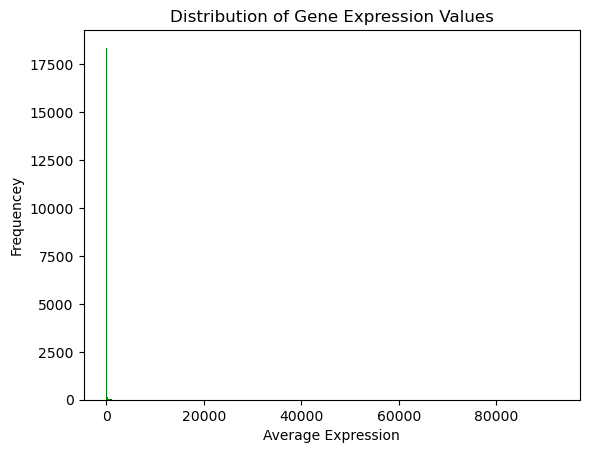

In [8]:
plt.hist(avg_expression, color = 'g', bins = 1000)
plt.title('Distribution of Gene Expression Values')
plt.xlabel('Average Expression')
plt.ylabel('Frequencey')

In [9]:
top_90 = np.percentile(avg_expression,q=90)
filtered = [i for i in avg_expression if i < top_90]

Text(0, 0.5, 'Frequencey')

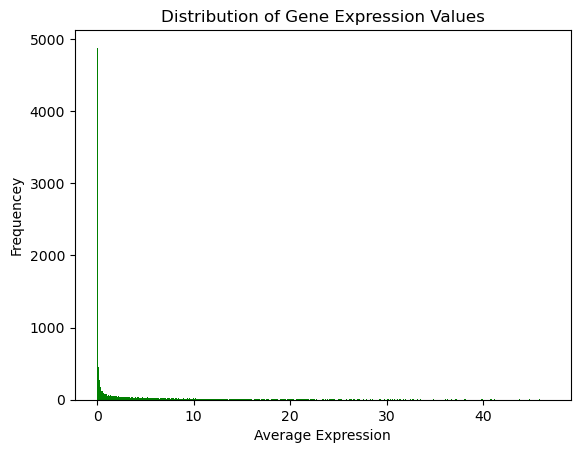

In [10]:
plt.hist(filtered, color = 'g', bins = 1000)
plt.title('Distribution of Gene Expression Values')
plt.xlabel('Average Expression')
plt.ylabel('Frequencey')

Text(0.5, 1.0, 'Average Gene Expression Box plots')

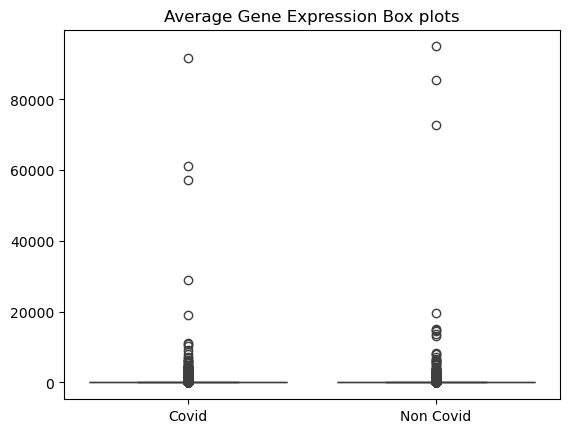

In [11]:
values = {
    'Covid': avg_expression_covid,
    'Non Covid': avg_expression_non_covid
}
sns.boxplot(values)
plt.title('Average Gene Expression Box plots')

In [12]:
change = 50
new_genes = []
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] < normal - normal*(change/100) or avg_expression_covid[i] > normal + normal*(change/100):
            new_genes.append(name)

In [13]:
len(new_genes)

6879

In [14]:
elevated_genes = []
change = 100
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] > normal + normal*(change/100):
            elevated_genes.append((name,avg_expression_covid[i]))

In [15]:
len(elevated_genes)
elevated_genes = sorted(elevated_genes,key= lambda x: -x[1])

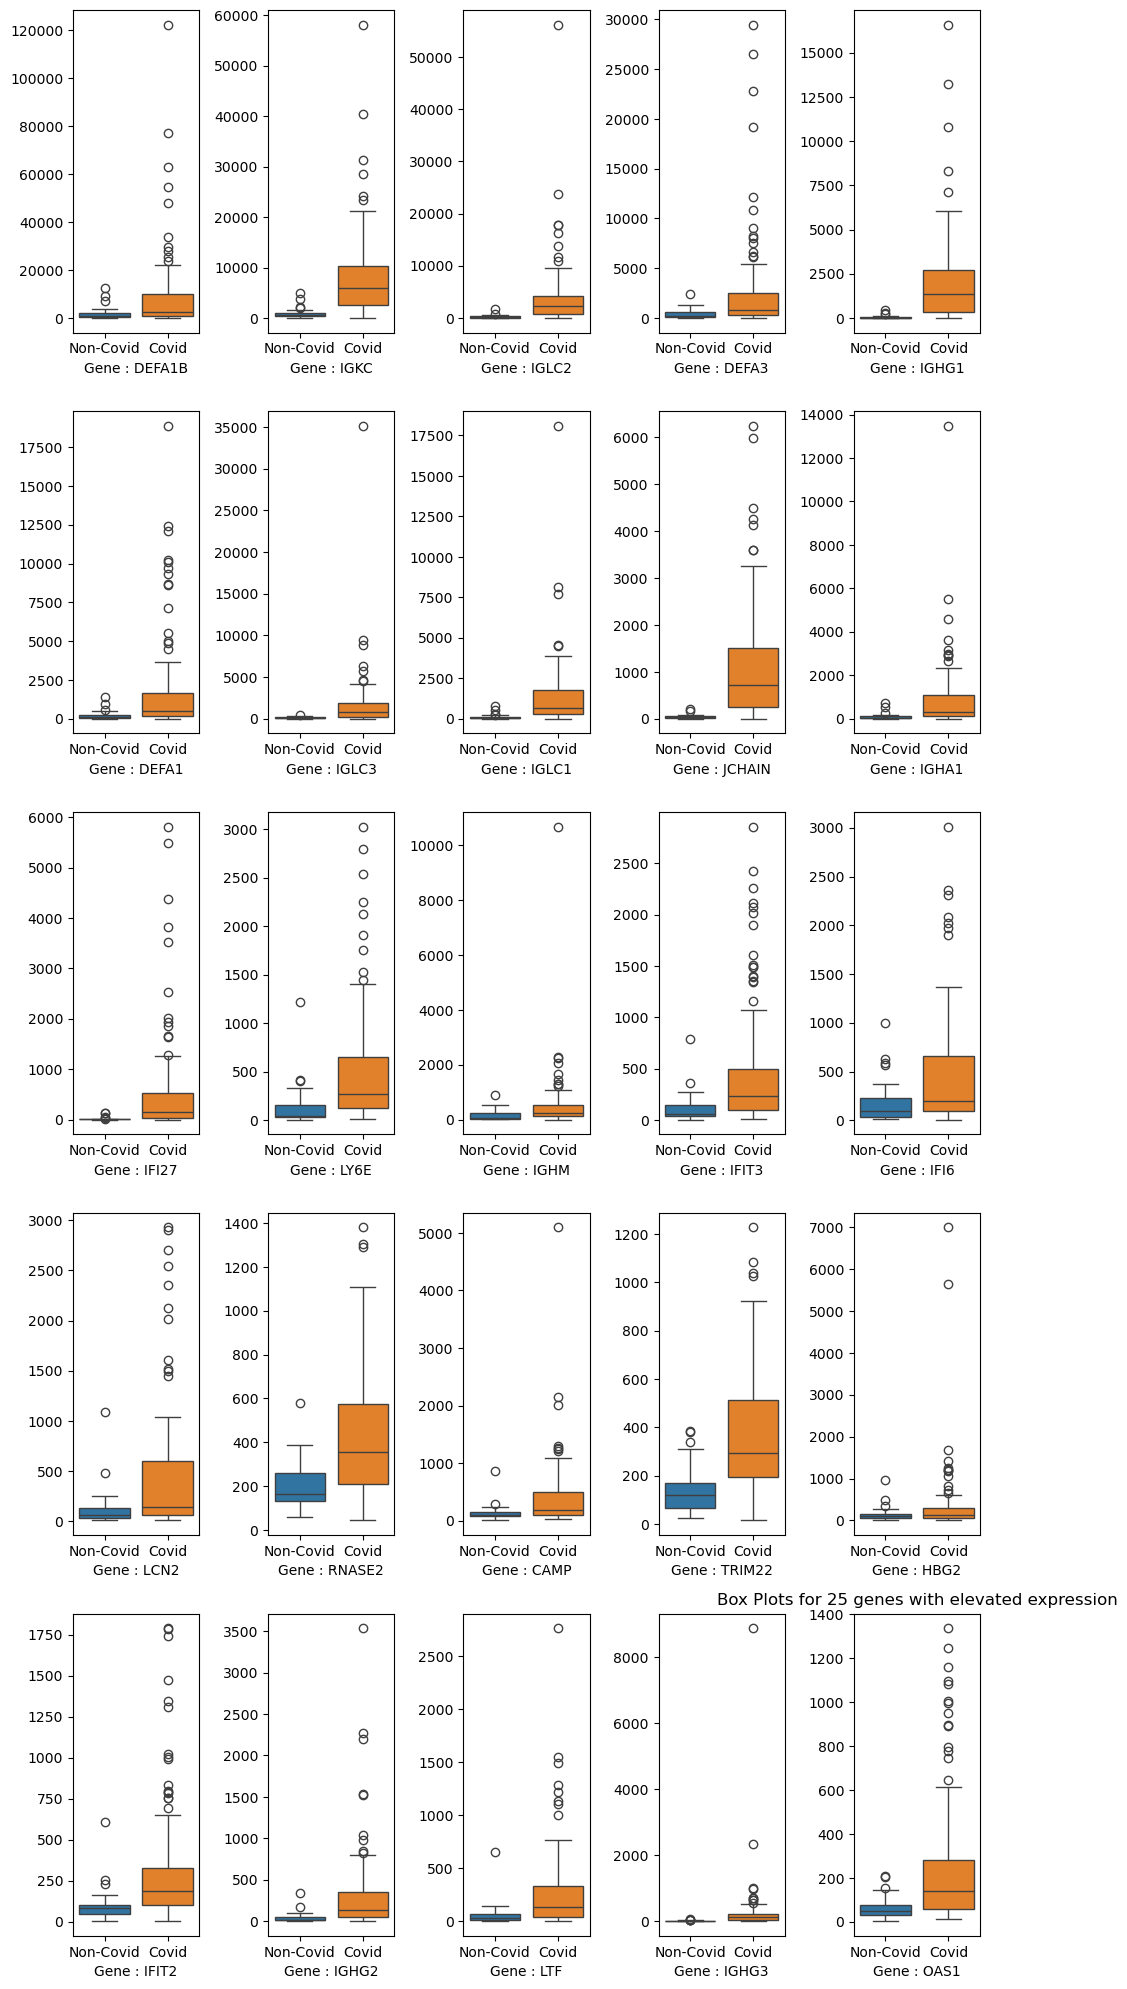

In [16]:
plt.figure(figsize=(10,20))
for i,val in enumerate(elevated_genes[:25]):
    plt.subplot(5,5,i+1)
    sns.boxplot({'Non-Covid':nc[val[0]],'Covid': cc[val[0]]})
    plt.xlabel(f'Gene : {val[0]}')
plt.title('Box Plots for 25 genes with elevated expression')
plt.tight_layout()

    

IFI27, IFI6, IFIT3, IFIT2, OAS1, LY6E, TRIM22 - antiviral defense and interferon-stimulated responses
DEFA1, DEFA1B, DEFA3, LCN2, CAMP, LTF, RNASE2 - antimicrobial defense, neutrophil granules, and inflammatory responses

In [17]:
depressed_genes = []
change = 50
for i,name in enumerate(genes):
    normal = avg_expression_non_covid[i]
    normal = avg_expression_non_covid[i]
    if normal == 0:
        pass
    else:
        if avg_expression_covid[i] < normal - normal*(change/100):
            depressed_genes.append((name,avg_expression_covid[i]))

In [18]:
len(depressed_genes)
depressed_genes = sorted(depressed_genes,key= lambda x: -x[1])

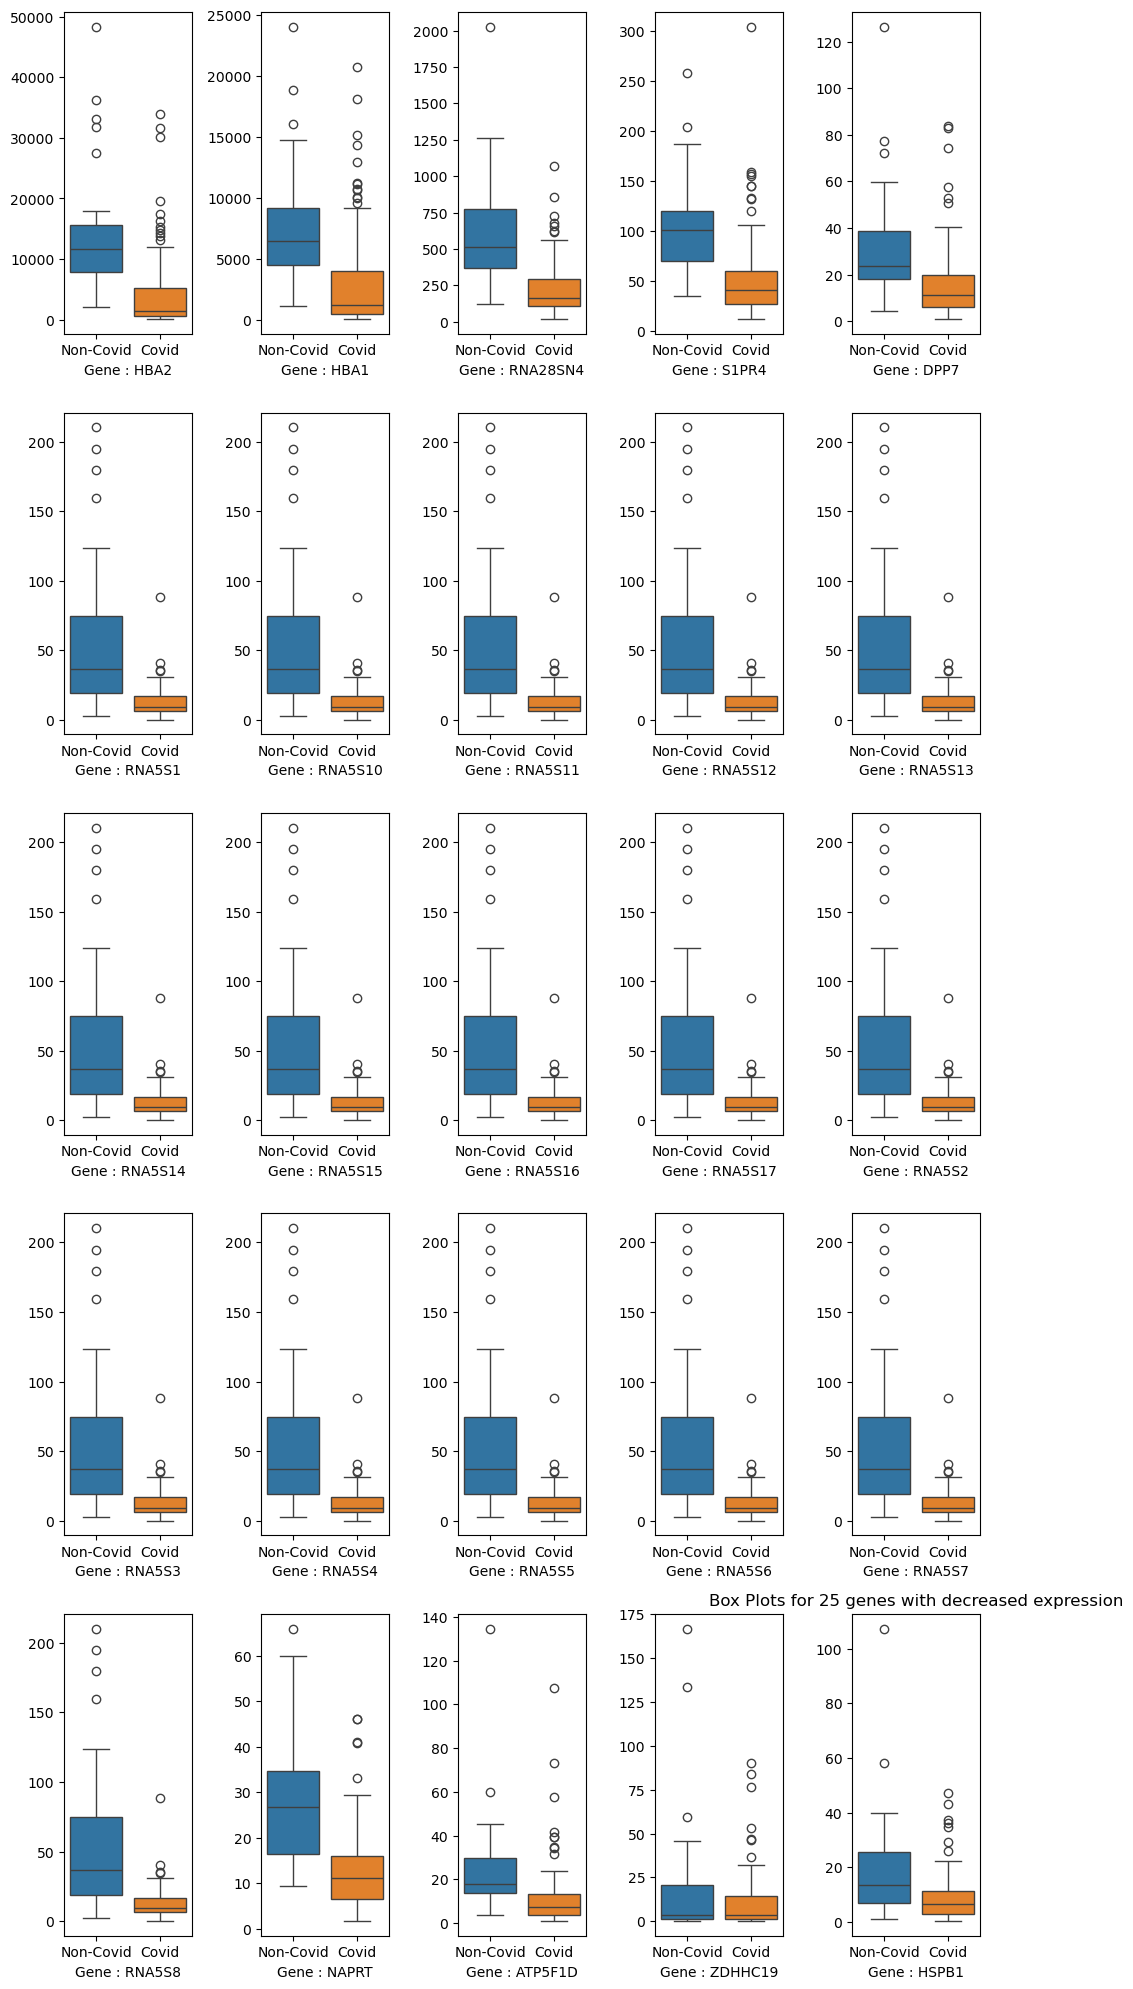

In [19]:
plt.figure(figsize=(10,20))
for i,val in enumerate(depressed_genes[:25]):
    plt.subplot(5,5,i+1)
    sns.boxplot({'Non-Covid':nc[val[0]],'Covid': cc[val[0]]})
    plt.xlabel(f'Gene : {val[0]}')
plt.title('Box Plots for 25 genes with decreased expression')
plt.tight_layout()


**Statistically Significant expression range**
 - Minimum Increase in epxression in the class sizes 26 and 102 to be considered statistically significant.